In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("customer_behavior_cleaned.csv")


In [3]:
df.head()

,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,Middle-aged,14.0
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,Young Adult,14.0
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle-aged,7.0
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young Adult,7.0
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle-aged,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              3900 non-null   int64  
 1   age                      3900 non-null   int64  
 2   gender                   3900 non-null   object 
 3   item_purchased           3900 non-null   object 
 4   category                 3900 non-null   object 
 5   purchase_amount          3900 non-null   int64  
 6   location                 3900 non-null   object 
 7   size                     3900 non-null   object 
 8   color                    3900 non-null   object 
 9   season                   3900 non-null   object 
 10  review_rating            3900 non-null   float64
 11  subscription_status      3900 non-null   object 
 12  shipping_type            3900 non-null   object 
 13  discount_applied         3900 non-null   object 
 14  previous_purchases      

In [7]:
df["purchase_frequency_days"].value_counts()

purchase_frequency_days
14.0    1089
90.0     584
30.0     553
7.0      539
Name: count, dtype: int64

In [15]:
df["purchase_frequency_days"].isnull().sum()

np.int64(0)

In [10]:
df.groupby('frequency_of_purchases')['purchase_frequency_days'].agg(
    ['count', 'min', 'max']
)

,count,min,max
frequency_of_purchases,,,
Annually,0,NaN,NaN
Bi-Weekly,547,14.0,14.0
Every 3 Months,584,90.0,90.0
Fortnightly,542,14.0,14.0
Monthly,553,30.0,30.0
Quarterly,0,NaN,NaN
Weekly,539,7.0,7.0


In [12]:
frequency_mapping = {
    'Weekly': 7,
    'Bi-Weekly': 14,
    'Fortnightly': 14,
    'Monthly': 30,
    'Every 3 Months': 90,
    'Quarterly': 90,
    'Annually': 365
}
df["purchase_frequency_days"]=df["frequency_of_purchases"].map(frequency_mapping)

In [13]:
df.groupby('frequency_of_purchases')['purchase_frequency_days'].agg(
    ['count', 'min', 'max']
)

,count,min,max
frequency_of_purchases,,,
Annually,572,365,365
Bi-Weekly,547,14,14
Every 3 Months,584,90,90
Fortnightly,542,14,14
Monthly,553,30,30
Quarterly,563,90,90
Weekly,539,7,7


In [14]:
df['purchase_frequency_days'].isnull().sum()

np.int64(0)

In [16]:
df["age"].describe()

count    3900.000000
mean       44.068462
std        15.207589
min        18.000000
25%        31.000000
50%        44.000000
75%        57.000000
max        70.000000
Name: age, dtype: float64

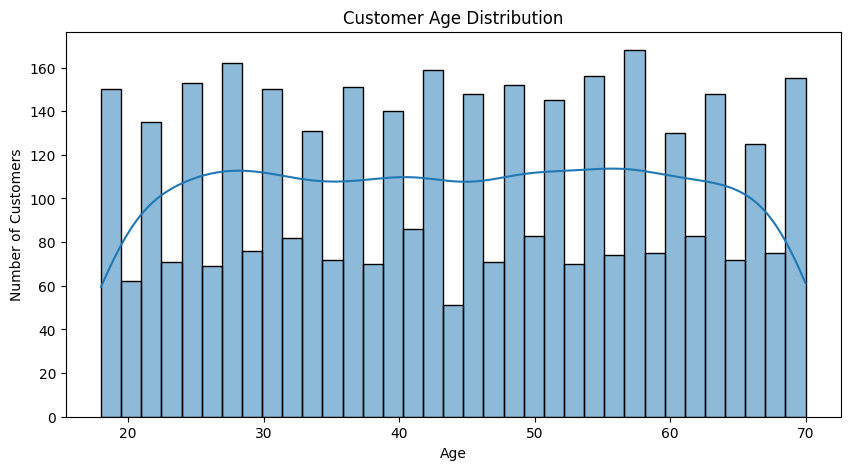

In [19]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='age',bins=35,kde=True)
plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

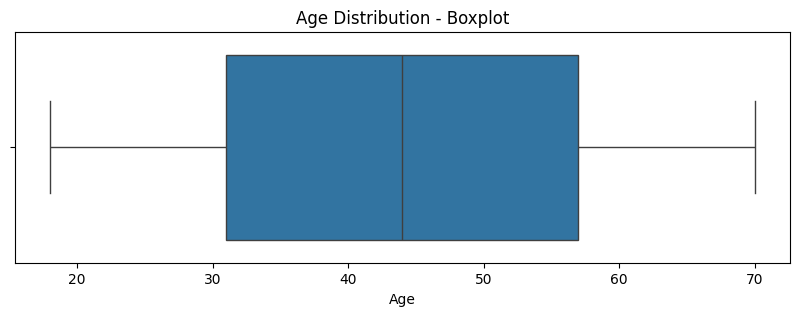

In [20]:
plt.figure(figsize=(10,3))

sns.boxplot(x=df['age'])

plt.title('Age Distribution - Boxplot')
plt.xlabel('Age')

plt.show()

In [24]:
df['age'].describe()

count    3900.000000
mean       44.068462
std        15.207589
min        18.000000
25%        31.000000
50%        44.000000
75%        57.000000
max        70.000000
Name: age, dtype: float64

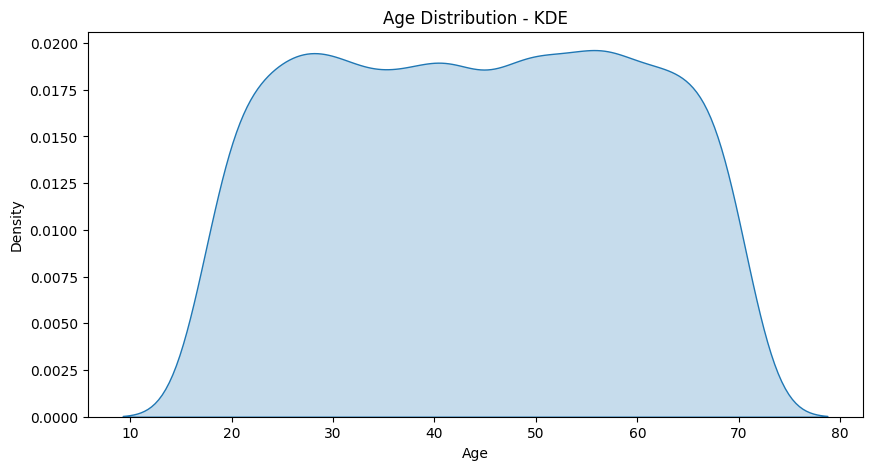

In [32]:
plt.figure(figsize=(10,5))

sns.kdeplot(
    data=df,
    x='age',
    fill=True,
    bw_adjust=1
)
plt.title('Age Distribution - KDE')
plt.xlabel('Age')
plt.ylabel('Density')
plt.show()

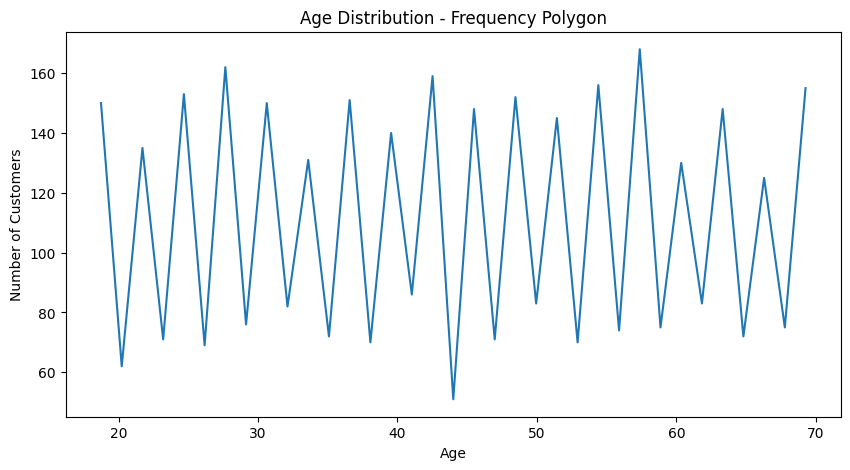

In [29]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='age',bins=35,stat='count',element='poly',fill=False)
plt.title('Age Distribution - Frequency Polygon')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

In [33]:
print("Skewness:", df['age'].skew())
print("Kurtosis:", df['age'].kurt())

Skewness: -0.0063797217209905395
Kurtosis: -1.1950871489241808


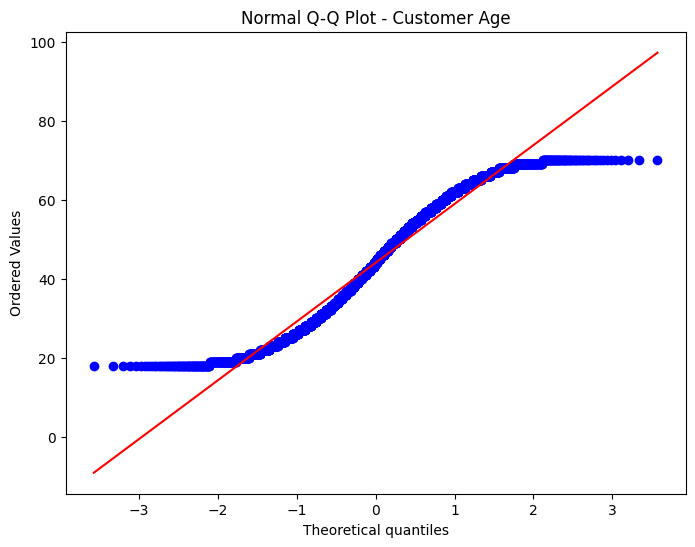

In [36]:
import scipy.stats as stats
plt.figure(figsize=(8, 6))

stats.probplot(
    df['age'],
    dist='norm',
    plot=plt
)
plt.title('Normal Q-Q Plot - Customer Age')
plt.show()

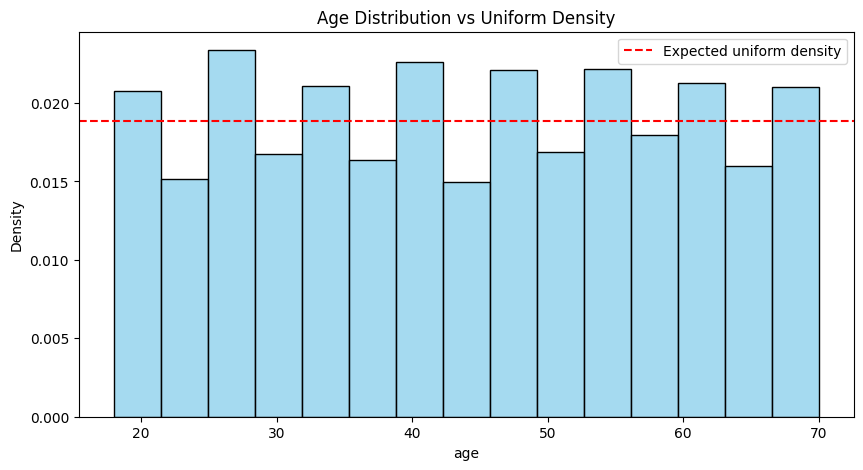

In [39]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['age'],
    bins=15,
    stat='density',
    color='skyblue'
)

plt.axhline(
    y=1/53,
    color='red',
    linestyle='--',
    label='Expected uniform density'
)
plt.title('Age Distribution vs Uniform Density')
plt.legend()
plt.show()

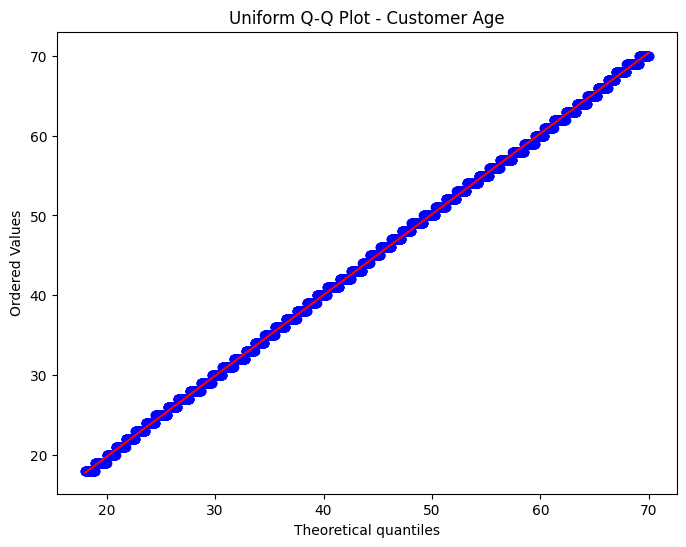

In [40]:
plt.figure(figsize=(8, 6))

stats.probplot(
    df['age'],
    dist='uniform',
    sparams=(18, 52),
    plot=plt
)

plt.title('Uniform Q-Q Plot - Customer Age')
plt.show()

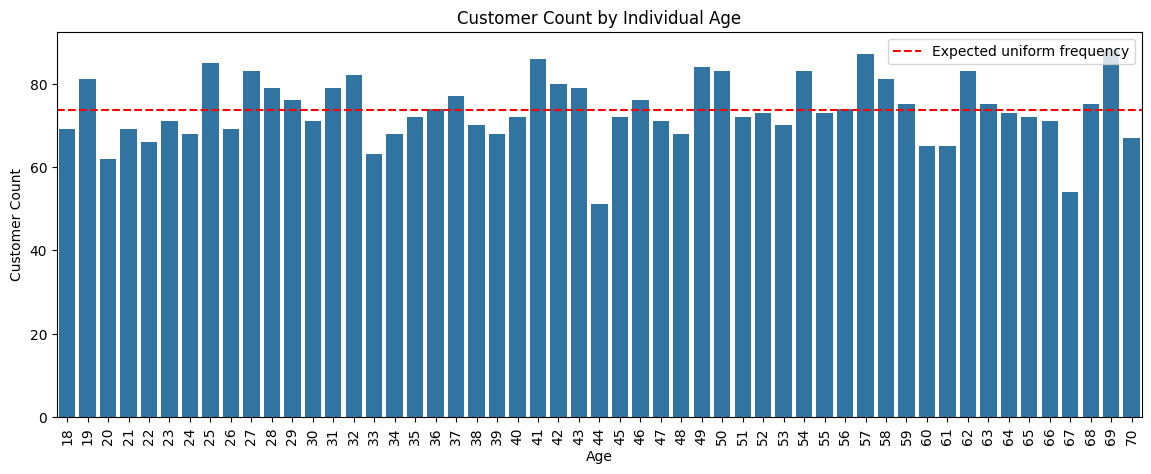

In [42]:
age_counts = df['age'].value_counts().sort_index()
plt.figure(figsize=(14, 5))

sns.barplot(
    x=age_counts.index,
    y=age_counts.values
)

plt.axhline(
    y=len(df)/53,
    color='red',
    linestyle='--',
    label='Expected uniform frequency'
)

plt.title('Customer Count by Individual Age')
plt.xlabel('Age')
plt.ylabel('Customer Count')
plt.legend()
plt.xticks(rotation=90)
plt.show()